Advantages of using a Bayesian neural network over simple Bayesian inference:

1. No need to have an analytical expression for the likelihood which in general is complicated. Just look at the likelihood for the simple TLS system.
2. Faster inference since you just pass an input to the neural network instead of using MCMC sampling to compute the posterior mean (much better for edge devices)

Advantage over bootstrapping:

1. Only need to train one model

$$
\begin{align*}
H &= \Delta a^\dag a + \Omega (a +  a^\dag) \\ 
  &= \Delta \sigma^\dag \sigma + \Omega (\sigma + \sigma^\dag)\\

C &= \sqrt{\gamma} a = \sqrt{\gamma} \sigma  \\

&\text{where} \qquad \sigma = \ket{0}\bra{1} = \ket{g}\bra{e}

\end{align*}
$$

In [1]:
import cmath 

import numpy as np
from numpy import cosh, cos, exp
import arviz as az
import pymc as pm
from scipy.integrate import quad
from functools import partial

import matplotlib.pyplot as plt

In [ ]:
val_deltas = np.load("../validation-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy")
print(val_deltas.shape)

(40,)


In [3]:
val_trajs = np.load("../validation-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy")
#print(trajs)
print(val_trajs .shape)
# unique_deltas = np.unique(deltas)
# print(len(unique_deltas))

(40, 10000, 48)


In [4]:
deltas = np.load('../training-trajectories/1D-delta/delta_rand_list-Delta-1D.npy')
print(deltas)
print(deltas.shape)
unique_deltas = np.unique(deltas)
print(len(unique_deltas))

[3.42129785 2.82497451 3.38907133 ... 2.84293035 3.94408452 3.68017995]
(4000000,)
4000000


In [5]:
taus = np.load('../training-trajectories/1D-delta/taus-Delta-1D.npy')
print(taus)
print(taus.shape)

[[12.73854975 39.84390694  4.3925545  ... 23.68072383 33.02604673
  44.72155646]
 [ 0.79340886 10.40239328  6.62897469 ...  1.02364835 15.04030332
  29.46332385]
 [ 6.12169971  5.13025833  7.50248598 ... 16.01789288  4.39864102
   8.7555393 ]
 ...
 [ 2.08528715  0.99922776 37.44840416 ...  3.1665483   0.46231649
   8.44733478]
 [ 4.01267272 16.94972109 17.36242506 ... 48.38215145  6.46169332
  65.56516331]
 [36.93949453  0.73763226 14.58889307 ... 21.5365938  51.74215466
   5.96333061]]
(4000000, 48)


The likelihood (waiting-time distribution) is given by:

$$
w(\tau;\Omega,\Delta, \gamma) = \frac{8\gamma\Omega^2}{R} \exp{(-\gamma\tau/2)}\left( \cosh{\left(\frac{\tau\sqrt{\gamma^2-4(\Delta^2+4\Omega^2)+R}}{2\sqrt{2}}\right)} - \cosh{\left(\frac{\tau\sqrt{\gamma^2-4(\Delta^2+4\Omega^2)-R}}{2\sqrt{2}}\right)} \right) 
$$

In [6]:
# def wait_time_dist(tau: float, omega: float, delta: float = 1,  gamma: float = 1) -> float:
#     """
#     Compute the wait time distribution for a given omega, delta, and tau.
#     Note we use cmath for complex numbers to handle the square root of negative numbers.
#     """

#     R = cmath.sqrt( (gamma**2 + 4*(delta**2 + 4*(omega**2) ) )**2  - 64*(gamma**2)*(omega**2) )
#     prefactor_term = (8 * gamma * (omega**2) / R) * np.exp(-gamma*tau/2)
    
#     sum_term = 0
#     for eta in {-1.0, 1.0}:
#         sum_term += eta*np.cosh( (tau*cmath.sqrt(gamma**2 - 4*(delta**2 + 4*(omega**2)) + eta*R ) ) / (2*cmath.sqrt(2)) )

#     prob_density = prefactor_term * sum_term

#     return prob_density

def wait_time_dist(tau: float, omega: float, delta: float, gamma: float = 1) -> float:
    """
    Calculates the waiting time distribution of a coherently driven two-level system based on omega and delta.
    
    We set \gamma = 1 as in the paper.

    Args:
        tau: Time delay.
        omega (float): Parameter omega.
        delta (float): Parameter delta.

    Returns:
        float: Probability density, w(tau).
    """
    
    R = np.sqrt( (1 + 4 * (delta**2+ 4*omega**2))**2 - 64*omega**2)
    w_tau = 8*exp(-tau/2)*omega**2 / R  
    
    A = np.sqrt(-64*omega**2+(1+4*delta**2+16*omega**2)**2)
    sum_term1 = -cos(tau*np.sqrt(-1 + 4*delta**2 + 16*omega**2 + A) / (2*np.sqrt(2)))
    sum_term2 = cosh(tau*np.sqrt(1 - 4*delta**2 - 16*omega**2 + A) / (2*np.sqrt(2)))
    
    w_tau *= (sum_term1 + sum_term2)

    return w_tau

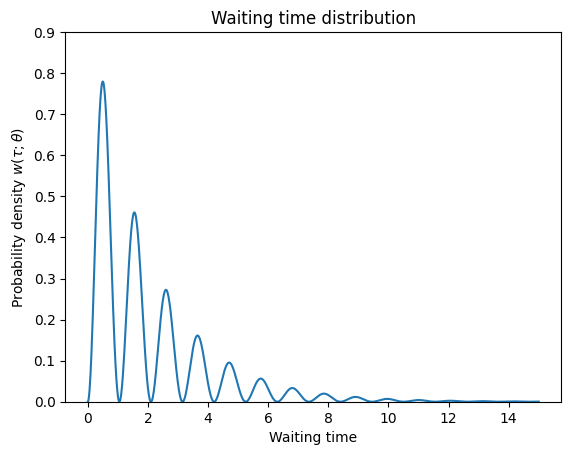

In [7]:
support = np.linspace(0.0, 15, 1000)
gamma = 0.6
prob_densities = [ wait_time_dist(support[i], omega=5*gamma, delta=0*deltas[0], gamma=gamma) for i in range(len(support)) ]

plt.plot(support, prob_densities)
plt.title('Waiting time distribution')
plt.ylim(0, 0.9)
plt.xlabel('Waiting time')
# plt.xscale('log')
plt.ylabel(r'Probability density $w(\tau; \theta)$');

In [8]:
partial_wait_time_dist = partial(wait_time_dist, omega=5, delta=0*deltas[0], gamma=gamma)

result, error = quad(partial_wait_time_dist, 0, 1000)

print(f"Numerical integral: {result}\nError estimate: {error}")

Numerical integral: 1.0000000002804204
Error estimate: 1.2899284892518815e-08


In [ ]:
def logp_fn(value, delta):
        omega_val = 1
        w = wait_time_dist(value, omega_val, delta)
        # Add small epsilon to avoid log(0)
        return np.log(w + 1e-12)

rmses = [] 

for i in range(val_deltas.shape[0]):
    
    delta_true = val_deltas[i]
    estimates = []
    
    for j in range(3):#range(val_trajs.shape[1]):
        tau_list = val_trajs[i, j]

        with pm.Model() as m:
            # define uniform prior on delta [0, 10]
            delta = pm.Uniform("delta", 0, 2.1)

            # define likelihood (waiting-time distribution)
            pm.CustomDist("likelihood", delta, logp=logp_fn, observed=tau_list)

            trace = pm.sample(5_000, nuts_sampler="nutpie", progressbar=False, nuts_sampler_kwargs=dict(backend="jax"))

        
        summary = az.summary(trace, hdi_prob=0.95, var_names=["delta"])
        
        estimates.append(summary['mean']['delta'])
        #print(f"Trajectory {j+1} - True delta: {delta_true}, Estimated delta: {summary['mean']['delta']}")
    
    rmse = np.sqrt(np.mean((estimates - delta_true)**2))
    rmses.append(rmse)
    print(f"RMSE for ∆ = {delta_true:.3f}: {rmse}")

/home/amanuelant/.local/lib/python3.10/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


RMSE for ∆ = 0.000: 0.24701012125012206
RMSE for ∆ = 0.054: 0.2018488215114523
RMSE for ∆ = 0.108: 0.23040436540489667
RMSE for ∆ = 0.162: 0.0768659018284787
RMSE for ∆ = 0.215: 0.0696577290115416
RMSE for ∆ = 0.269: 0.03767644878301841
RMSE for ∆ = 0.323: 0.17819747262655858
RMSE for ∆ = 0.377: 0.0811568962848855
RMSE for ∆ = 0.431: 0.10204512286528798
RMSE for ∆ = 0.485: 0.15608649551719794
RMSE for ∆ = 0.538: 0.22833389337526167
RMSE for ∆ = 0.592: 0.15789477933491933
RMSE for ∆ = 0.646: 0.06955000471472692
RMSE for ∆ = 0.700: 0.15769379611555218
RMSE for ∆ = 0.754: 0.2231462049797042
RMSE for ∆ = 0.808: 0.0657506346479446
RMSE for ∆ = 0.862: 0.20288807750114463


arviz - WARNING - Array contains NaN-value.


In [ ]:
plt.plot(val_deltas, rmses)
plt.title('RMSE vs Delta')
plt.xlabel('Delta')

In [ ]:


num_trajs = 40
estimates = []

for i in range(num_trajs):
    
    delta_true = deltas[i]
    tau_list = taus[i]
    
    with pm.Model() as m:
        # define uniform prior on delta [0, 10]
        delta = pm.Uniform("delta", 0, 10)

        # define likelihood (waiting-time distribution)
        pm.CustomDist("likelihood", delta, logp=logp_fn, observed=tau_list)

        trace = pm.sample(40_000, nuts_sampler="nutpie", progressbar=False)


    print(f"True delta: {delta_true}")
    
    summary = az.summary(trace, hdi_prob=0.95, var_names=["delta"])
    
    estimates.append(summary['mean']['delta'])
    
    print(f"Posterior mean delta: {summary['mean']['delta']}\n")

True delta: 3.4212978499040685
Posterior mean delta: 3.603

True delta: 2.8249745127315595
Posterior mean delta: 2.659

True delta: 3.3890713337653406
Posterior mean delta: 3.815

True delta: 1.4237393404535732
Posterior mean delta: 1.374

True delta: 4.95416927105384
Posterior mean delta: 5.179

True delta: 4.069549314646515
Posterior mean delta: 3.836

True delta: 3.193117252642189
Posterior mean delta: 3.084

True delta: 2.8106515015437856
Posterior mean delta: 2.906

True delta: 1.787430802174067
Posterior mean delta: 1.944

True delta: 1.6953106520328372
Posterior mean delta: 1.93

True delta: 4.525625136877968
Posterior mean delta: 4.145

True delta: 2.733395593463447
Posterior mean delta: 3.047

True delta: 0.40381217710040607
Posterior mean delta: 0.488

True delta: 3.538262725970953
Posterior mean delta: 3.768

True delta: 3.2219023189376634
Posterior mean delta: 3.627

True delta: 1.5792693860075917
Posterior mean delta: 1.978

True delta: 4.700970998709003
Posterior mean del

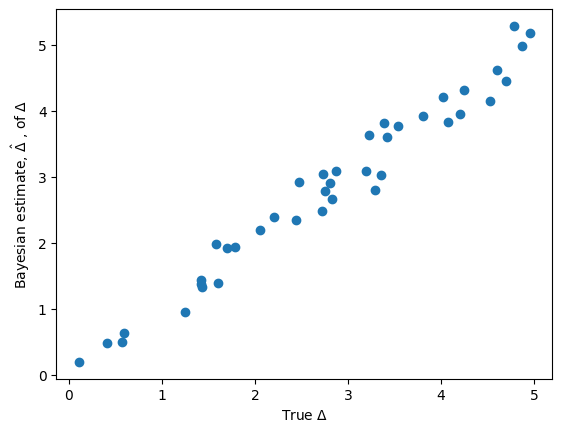

In [34]:
plt.plot(deltas[:num_trajs], [estimates[i] for i in range(num_trajs)], 'o')
plt.title('')
plt.xlabel(r'True $\Delta$')
plt.ylabel(r'Bayesian estimate, $\hat{\Delta}$ , of $\Delta$');

## 2-D case

In [8]:
d_ome = np.load('../tg/training-trajectories/2D-delta-omega/param_rand_list-2D.npy')
print(d_ome)
print(d_ome.shape)

[[1.40605712 3.77467714]
 [1.60676247 3.1426938 ]
 [2.99518697 1.9022824 ]
 ...
 [2.68033019 3.15101284]
 [1.24551066 3.74186732]
 [1.66629651 2.61797727]]
(4000000, 2)


In [9]:
taus = np.load('../tg/training-trajectories/2D-delta-omega/taus-2D.npy')
print(taus)
print(taus.shape)

[[ 1.09968202  3.13291034  2.72732946 ...  0.96803805  3.85899565
   2.31658659]
 [ 3.24711778  2.59998375  1.67711105 ...  1.3867556   1.26877088
   2.31478661]
 [18.69777603  4.08653471 10.47288218 ...  0.60705079  5.65842739
  14.86530452]
 ...
 [ 3.90190314  0.59702738  2.94033991 ...  2.27614672  7.78676203
   0.58439649]
 [ 2.17516569  5.36248621  1.18072969 ...  1.42068437  1.17423572
   1.50621844]
 [13.42452058  0.36924592  1.33056951 ...  1.75067859  0.85733393
   0.34474859]]
(4000000, 48)


In [11]:
def logp_fn(value, omega, delta):
        w = wait_time_dist(value, omega, delta)
        
        # Add small epsilon to avoid log(0)
        return np.log(w + 1e-12)

num_trajs = 1
estimates = []

for i in range(num_trajs):
    

    delta_true = d_ome[i, 0]
    omega_true = d_ome[i, 1]
    tau_list = taus[i]
    
    with pm.Model() as m:
        # define uniform prior on delta [0, 3]
        delta = pm.Uniform("delta", 0, 3)
        omega = pm.Uniform("omega", 0.25, 5)

        # define likelihood (waiting-time distribution)
        pm.CustomDist("likelihood", omega, delta, logp=logp_fn, observed=tau_list)

        trace = pm.sample(50_000, chains=10, cores=10, tune=5000, nuts_sampler="nutpie", progressbar=not False, target_accept=0.9)


    print(f"True delta: {delta_true}, True omega: {omega_true}")
    
    summary = az.summary(trace, hdi_prob=0.95, var_names=["delta", "omega"])
    estimates.append(summary['mean']['delta'])
    
    print(f"Posterior mean delta: {summary['mean']['delta']}, posterior mean omega: {summary['mean']['omega']}\n")

Progress,Draws,Divergences,Step Size,Gradients/Draw
,55000,4,0.45,11
,55000,2,0.49,11
,55000,1,0.49,3
,55000,1,0.53,3
,55000,1,0.50,5
,55000,0,0.51,11
,55000,0,0.51,3
,55000,1,0.48,1
,55000,0,0.50,11
,55000,0,0.51,1


True delta: 1.4060571177687278, True omega: 3.7746771407049433
Posterior mean delta: 1.176, posterior mean omega: 2.427

